# LungCT All-10 Pareto Visual Review

This notebook combines IDIR BE, DirectCP 4stage pTV-LCC+isoTV, DirectCP 4stage global-NCC+FD-BE, and uploaded pTVReg fields. It displays the screening table and saves all Pareto figures to disk.

In [1]:
%matplotlib inline

from pathlib import Path
import sys

import pandas as pd
from IPython.display import display, Markdown

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / 'scripts').exists() and REPO_ROOT.parent != REPO_ROOT:
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from scripts.reports.lungct_pareto_visual_review import (
    DEFAULT_CASE_ROWS,
    DEFAULT_OUTPUT_ROOT,
    DEFAULT_PTVPREP_ROOT,
    DEFAULT_PTVREG_ROOT,
    METHOD_FDBE,
    METHOD_IDIR,
    METHOD_PTVREG,
    METHOD_PTV_DIRECTCP,
    add_ratios,
    aggregate_case_rows,
    load_method_case_rows,
    load_ptvreg_case_rows,
    make_all_plots,
    save_review_artifacts,
    screening_table,
    validate_outputs,
)

pd.set_option('display.max_rows', 80)
pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 180)
print(f'Repo root: {REPO_ROOT}')
print(f'Output root: {DEFAULT_OUTPUT_ROOT}')

Repo root: /homebase/code_sync/inrorspline
Output root: /homebase/code_sync/inrorspline/experiments/2026-06-25_lungct_directcp4stage_global_ncc_fdbe_all10_alpha_sweep/pareto_visual_review


## Editable Exclusion Controls

Edit the dictionaries below to exclude by ratio-to-best-TRE weight or exact regularization weight. pTVReg is always retained as the reference point.

In [2]:
OUTPUT_ROOT = DEFAULT_OUTPUT_ROOT

EXCLUDE_BY_RATIO = {
    METHOD_IDIR: [],
    METHOD_PTV_DIRECTCP: [10.0, 100.0],
    METHOD_FDBE: [0.0, 0.001],
}

EXCLUDE_BY_WEIGHT = {
    METHOD_IDIR: [],
    METHOD_PTV_DIRECTCP: [],
    METHOD_FDBE: [],
}

print('EXCLUDE_BY_RATIO =', EXCLUDE_BY_RATIO)
print('EXCLUDE_BY_WEIGHT =', EXCLUDE_BY_WEIGHT)

EXCLUDE_BY_RATIO = {'idir_be_default_lungmask': [], 'direct_cp_32_16_8_4_ptv_lcc_isotv': [10.0, 100.0], 'direct_cp_32_16_8_4_global_ncc_fd_be': [0.0, 0.001]}
EXCLUDE_BY_WEIGHT = {'idir_be_default_lungmask': [], 'direct_cp_32_16_8_4_ptv_lcc_isotv': [], 'direct_cp_32_16_8_4_global_ncc_fd_be': []}


## Load Data And Validate pTVReg Fields

In [3]:
method_case_df = load_method_case_rows(DEFAULT_CASE_ROWS)
ptvreg_case_df = load_ptvreg_case_rows(DEFAULT_PTVREG_ROOT, DEFAULT_PTVPREP_ROOT)
case_df = add_ratios(pd.concat([method_case_df, ptvreg_case_df], ignore_index=True, sort=False))
mean_df = aggregate_case_rows(case_df)
table_df = screening_table(mean_df)
artifact_paths = save_review_artifacts(case_df, mean_df, table_df, OUTPUT_ROOT)

validation_cols = [
    'case_id',
    'source_saved_tre_phys_mean_mm',
    'source_recomputed_snap_tre_mean_mm',
    'source_tre_validation_abs_err',
    'source_saved_trestd_case_mm',
    'source_recomputed_snap_tre_std_mm',
    'source_trestd_validation_abs_err',
    'source_disp_h5py_shape',
]
ptvreg_validation = ptvreg_case_df[validation_cols].copy()

print(f'Trained-method case rows: {len(method_case_df)}')
print(f'pTVReg case rows: {len(ptvreg_case_df)}')
print(f'Combined case rows: {len(case_df)}')
print(f'Combined mean rows: {len(mean_df)}')
print('Saved artifacts:')
for name, path in artifact_paths.items():
    print(f'  {name}: {path}')

display(Markdown('### pTVReg field validation'))
display(ptvreg_validation)
assert (ptvreg_validation['source_tre_validation_abs_err'] < 1e-8).all()
assert (ptvreg_validation['source_trestd_validation_abs_err'] < 1e-8).all()

Trained-method case rows: 160
pTVReg case rows: 10
Combined case rows: 170
Combined mean rows: 17
Saved artifacts:
  case_rows: /homebase/code_sync/inrorspline/experiments/2026-06-25_lungct_directcp4stage_global_ncc_fdbe_all10_alpha_sweep/pareto_visual_review/combined_case_rows_with_ptvreg.csv
  mean_rows: /homebase/code_sync/inrorspline/experiments/2026-06-25_lungct_directcp4stage_global_ncc_fdbe_all10_alpha_sweep/pareto_visual_review/combined_mean_rows_with_ptvreg.csv
  screening_csv: /homebase/code_sync/inrorspline/experiments/2026-06-25_lungct_directcp4stage_global_ncc_fdbe_all10_alpha_sweep/pareto_visual_review/screening_table.csv
  screening_md: /homebase/code_sync/inrorspline/experiments/2026-06-25_lungct_directcp4stage_global_ncc_fdbe_all10_alpha_sweep/pareto_visual_review/screening_table.md


### pTVReg field validation

,case_id,source_saved_tre_phys_mean_mm,source_recomputed_snap_tre_mean_mm,source_tre_validation_abs_err,source_saved_trestd_case_mm,source_recomputed_snap_tre_std_mm,source_trestd_validation_abs_err,source_disp_h5py_shape
0,1,0.767141,0.767141,4.440892e-16,0.891749,0.891749,3.330669e-16,"(3, 94, 256, 256)"
1,2,0.750864,0.750864,2.220446e-16,0.898982,0.898982,2.220446e-16,"(3, 112, 256, 256)"
2,3,0.927378,0.927378,2.220446e-16,1.072600,1.072600,0.000000e+00,"(3, 104, 256, 256)"
3,4,1.265704,1.265704,2.220446e-16,1.259225,1.259225,6.661338e-16,"(3, 99, 256, 256)"
4,5,1.077725,1.077725,2.220446e-16,1.417158,1.417158,2.220446e-16,"(3, 106, 256, 256)"
5,6,0.831637,0.831637,3.330669e-16,0.924874,0.924874,0.000000e+00,"(3, 128, 512, 512)"
6,7,0.806061,0.806061,4.440892e-16,0.913381,0.913381,0.000000e+00,"(3, 136, 512, 512)"
7,8,1.014220,1.014220,2.220446e-16,1.292223,1.292223,6.661338e-16,"(3, 128, 512, 512)"
8,9,0.909508,0.909508,5.551115e-16,0.954036,0.954036,3.330669e-16,"(3, 128, 512, 512)"
9,10,0.840979,0.840979,4.440892e-16,0.969514,0.969514,0.000000e+00,"(3, 120, 512, 512)"


## Screening Table

In [4]:
display(table_df)

,Method,Weight,Ratio,Cases,Original Snap TRE,Original Sub TRE,FG stdLogJ,FG J<=0 %,FG BE,FG diffusion
0,IDIR BE,0.1000,0.010,10,1.317 +/- 0.656,1.408 +/- 0.634,0.3225 +/- 0.1128,0.2938 +/- 0.4034,0.007477 +/- 0.004523,0.023005 +/- 0.012893
1,IDIR BE,1.0000,0.100,10,1.046 +/- 0.200,1.159 +/- 0.166,0.2155 +/- 0.0553,0.0226 +/- 0.0451,0.002427 +/- 0.001137,0.012305 +/- 0.004662
2,IDIR BE,10.0000,1.000,10,1.017 +/- 0.176,1.133 +/- 0.137,0.1429 +/- 0.0348,2.47e-05 +/- 7.41e-05,0.000535 +/- 0.000181,0.007218 +/- 0.002864
3,IDIR BE,100.0000,10.000,10,1.085 +/- 0.212,1.196 +/- 0.163,0.1042 +/- 0.0269,0.0000 +/- 0.0000,0.000115 +/- 0.000036,0.005160 +/- 0.002281
4,IDIR BE,1000.0000,100.000,10,1.257 +/- 0.269,1.333 +/- 0.213,0.0789 +/- 0.0217,0.0000 +/- 0.0000,0.000020 +/- 0.000007,0.003827 +/- 0.001935
5,DirectCP 4stage pTV-LCC+isoTV,0.0011,0.010,10,1.320 +/- 0.713,1.393 +/- 0.704,0.6613 +/- 0.1110,2.6170 +/- 1.5585,0.132987 +/- 0.040223,0.098929 +/- 0.036288
6,DirectCP 4stage pTV-LCC+isoTV,0.0110,0.100,10,1.022 +/- 0.206,1.121 +/- 0.169,0.3974 +/- 0.0895,0.4137 +/- 0.3386,0.031837 +/- 0.010742,0.036033 +/- 0.012335
7,DirectCP 4stage pTV-LCC+isoTV,0.1100,1.000,10,0.922 +/- 0.152,1.049 +/- 0.119,0.1800 +/- 0.0496,0.0138 +/- 0.0193,0.002527 +/- 0.001038,0.010327 +/- 0.004408
8,DirectCP 4stage pTV-LCC+isoTV,1.1000,10.000,10,1.583 +/- 1.289,1.704 +/- 1.258,0.0946 +/- 0.0314,0.0000 +/- 0.0000,0.000192 +/- 0.000088,0.003711 +/- 0.001517
9,DirectCP 4stage pTV-LCC+isoTV,11.0000,100.000,10,6.809 +/- 3.425,6.581 +/- 3.310,0.0119 +/- 0.0028,0.0000 +/- 0.0000,3.88e-07 +/- 7.86e-08,0.000030 +/- 0.000013


## Pareto Figures

Each ellipse is centered at the method/weight all-case mean. Width is one standard deviation on the regularity axis, and height is one standard deviation on original snap TRE.

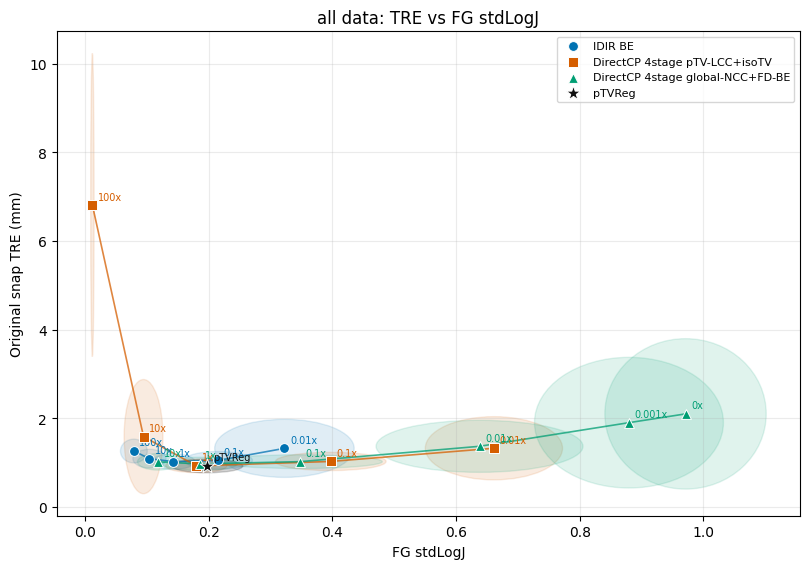

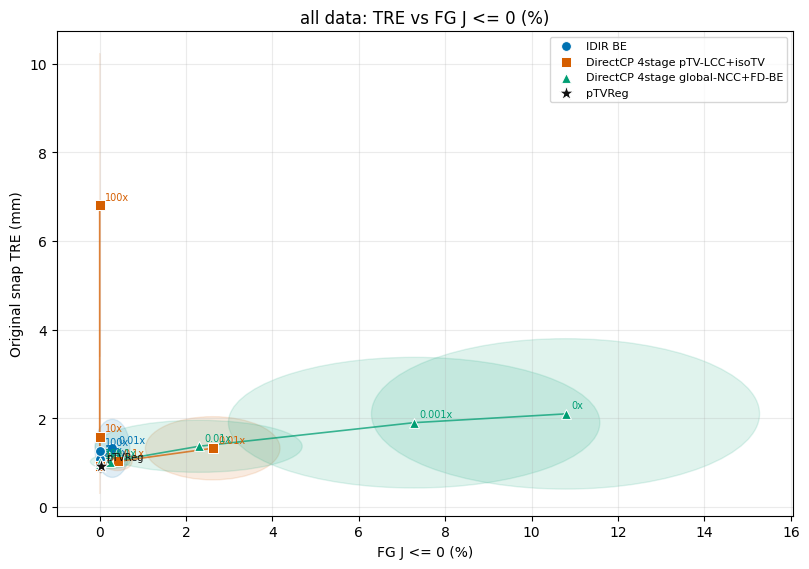

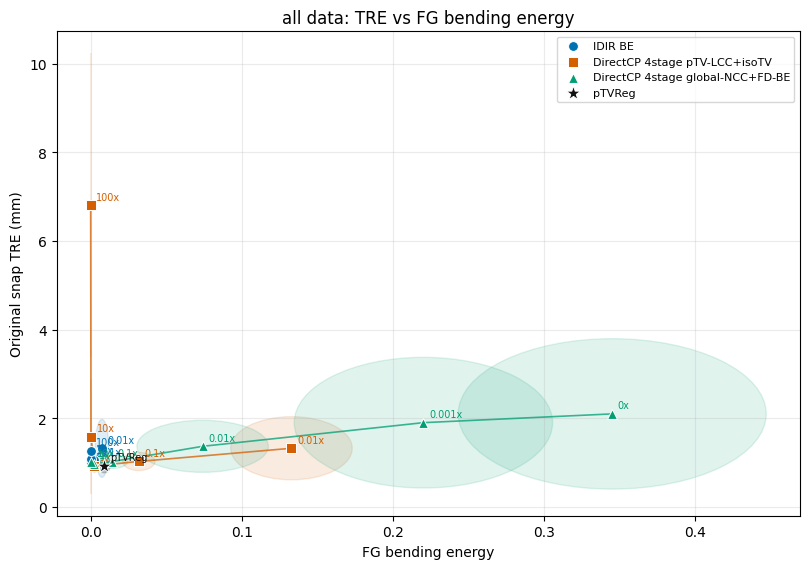

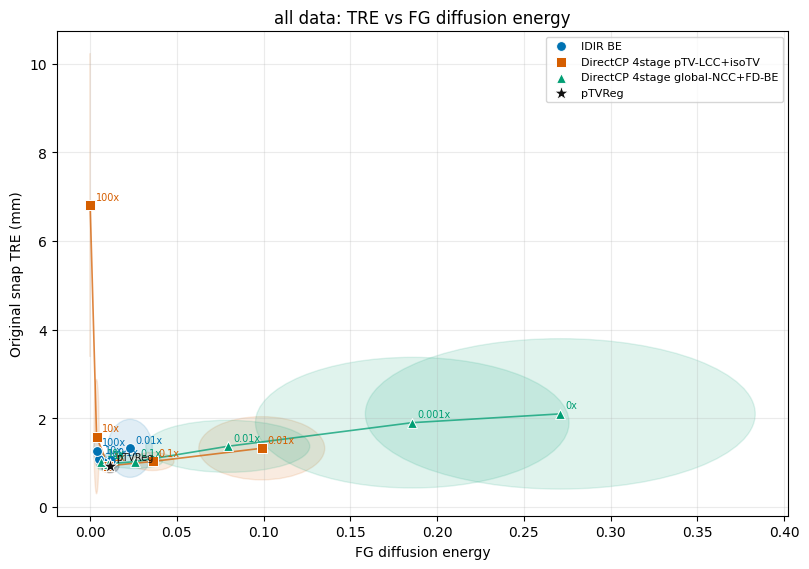

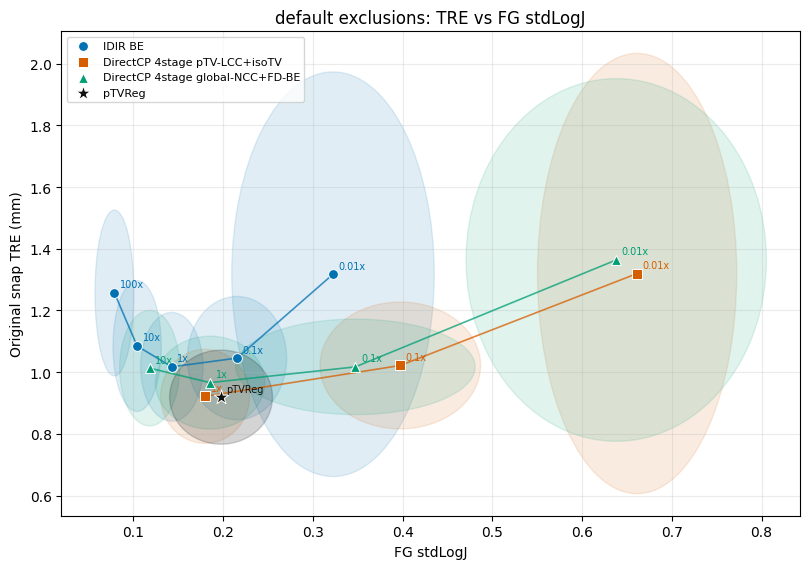

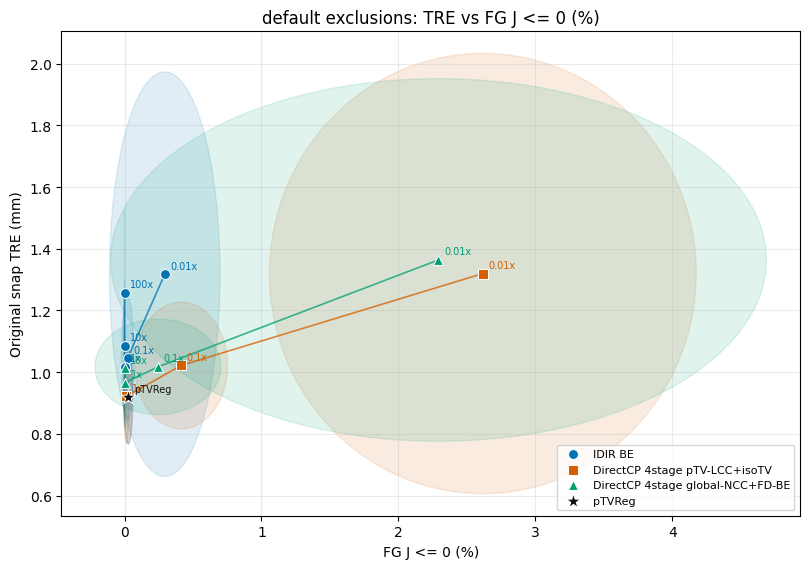

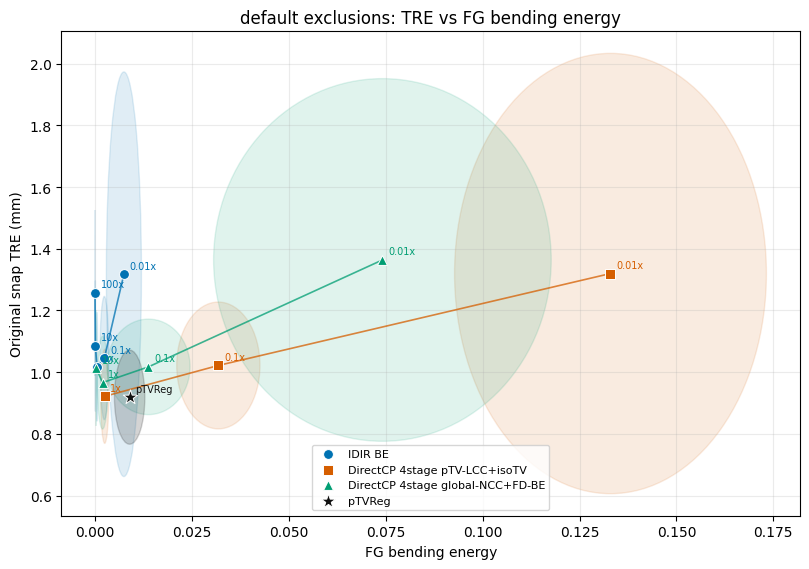

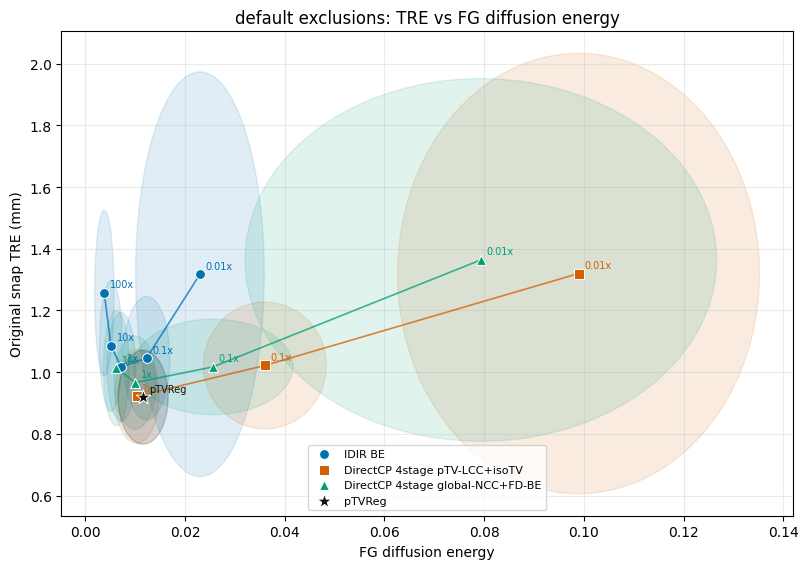

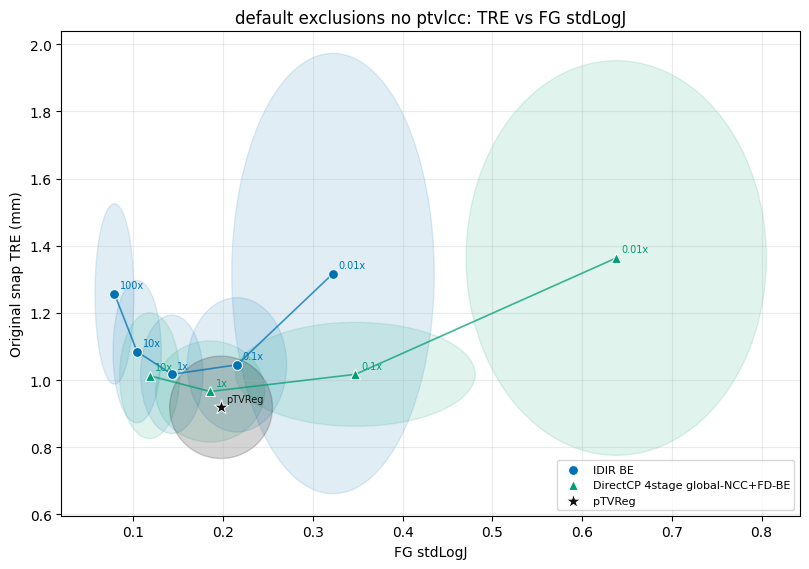

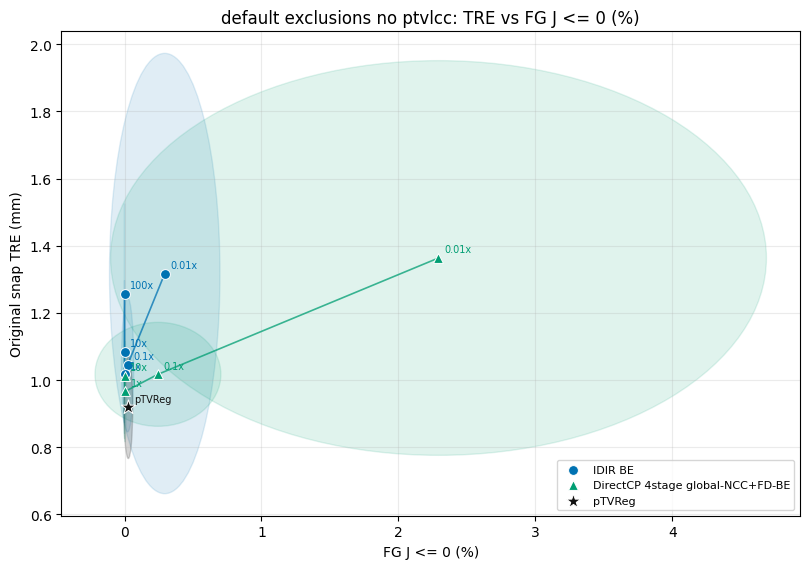

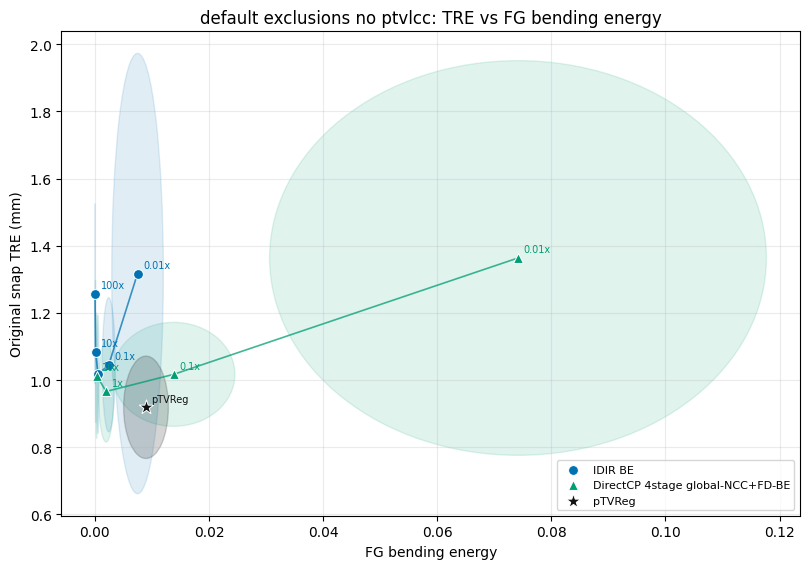

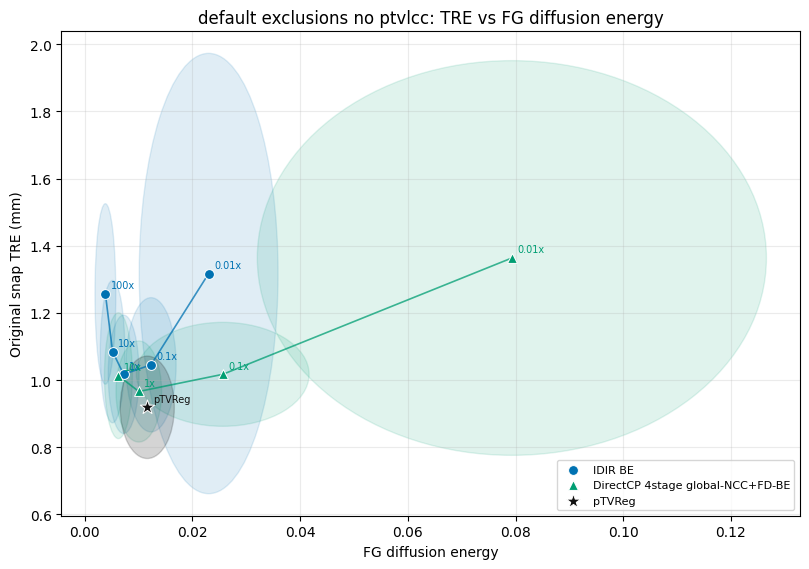

### Saved figure paths

**all_data**

/homebase/code_sync/inrorspline/experiments/2026-06-25_lungct_directcp4stage_global_ncc_fdbe_all10_alpha_sweep/pareto_visual_review/plots/all_data/original_snap_tre_vs_fg_logj_std.png
/homebase/code_sync/inrorspline/experiments/2026-06-25_lungct_directcp4stage_global_ncc_fdbe_all10_alpha_sweep/pareto_visual_review/plots/all_data/original_snap_tre_vs_fg_jdet_le0_pct.png
/homebase/code_sync/inrorspline/experiments/2026-06-25_lungct_directcp4stage_global_ncc_fdbe_all10_alpha_sweep/pareto_visual_review/plots/all_data/original_snap_tre_vs_fg_bending_energy.png
/homebase/code_sync/inrorspline/experiments/2026-06-25_lungct_directcp4stage_global_ncc_fdbe_all10_alpha_sweep/pareto_visual_review/plots/all_data/original_snap_tre_vs_fg_diffusion_l2.png


**default_exclusions**

/homebase/code_sync/inrorspline/experiments/2026-06-25_lungct_directcp4stage_global_ncc_fdbe_all10_alpha_sweep/pareto_visual_review/plots/default_exclusions/original_snap_tre_vs_fg_logj_std.png
/homebase/code_sync/inrorspline/experiments/2026-06-25_lungct_directcp4stage_global_ncc_fdbe_all10_alpha_sweep/pareto_visual_review/plots/default_exclusions/original_snap_tre_vs_fg_jdet_le0_pct.png
/homebase/code_sync/inrorspline/experiments/2026-06-25_lungct_directcp4stage_global_ncc_fdbe_all10_alpha_sweep/pareto_visual_review/plots/default_exclusions/original_snap_tre_vs_fg_bending_energy.png
/homebase/code_sync/inrorspline/experiments/2026-06-25_lungct_directcp4stage_global_ncc_fdbe_all10_alpha_sweep/pareto_visual_review/plots/default_exclusions/original_snap_tre_vs_fg_diffusion_l2.png


**default_exclusions_no_ptvlcc**

/homebase/code_sync/inrorspline/experiments/2026-06-25_lungct_directcp4stage_global_ncc_fdbe_all10_alpha_sweep/pareto_visual_review/plots/default_exclusions_no_ptvlcc/original_snap_tre_vs_fg_logj_std.png
/homebase/code_sync/inrorspline/experiments/2026-06-25_lungct_directcp4stage_global_ncc_fdbe_all10_alpha_sweep/pareto_visual_review/plots/default_exclusions_no_ptvlcc/original_snap_tre_vs_fg_jdet_le0_pct.png
/homebase/code_sync/inrorspline/experiments/2026-06-25_lungct_directcp4stage_global_ncc_fdbe_all10_alpha_sweep/pareto_visual_review/plots/default_exclusions_no_ptvlcc/original_snap_tre_vs_fg_bending_energy.png
/homebase/code_sync/inrorspline/experiments/2026-06-25_lungct_directcp4stage_global_ncc_fdbe_all10_alpha_sweep/pareto_visual_review/plots/default_exclusions_no_ptvlcc/original_snap_tre_vs_fg_diffusion_l2.png


In [5]:
plot_paths = make_all_plots(mean_df, OUTPUT_ROOT, EXCLUDE_BY_RATIO, EXCLUDE_BY_WEIGHT)
display(Markdown('### Saved figure paths'))
for subset_name, paths in plot_paths.items():
    display(Markdown(f'**{subset_name}**'))
    for path in paths:
        print(path)

## Output Check

In [6]:
status = validate_outputs(OUTPUT_ROOT)
display(status)
assert status['ok'], status

{'ok': True, 'missing_or_empty': [], 'expected_count': 16}